In [2]:
import numpy as np
import matplotlib.pyplot as plt
import warnings

def local_action(path, tau, x, delta_tau, m, omega):
    N_tau = len(path)

    # Every site needs two neighbours but the array only has indicies from
    # 0 to N_tau-1, so the two ends would run off the array
    # the %N wraps the values around so the periodic boundary conditions are satisfied
    left = path[(tau - 1) % N_tau]
    right = path[(tau + 1) % N_tau] #double check modulo

    kinetic = (m / (2 * delta_tau) 
               * ((x - left)**2 + (right - x)**2))

    potential = (delta_tau
        * 0.5 * m * (omega**2) * (x**2))
    
    return kinetic + potential

def metropolis_sweep(path, delta_tau):
   
    #for every lattice site:
    #choose a site               (1)
    #propose a new x             (2)
    #calculate ΔS                (3)
    #decide whether to accept    (4)

    acceptance = 0
    N_tau = len(path) #define number of elements in time lattice

    for i in range(N_tau):
        tau = np.random.randint(N_tau) #(1), choosing random site to start at
        j = np.random.uniform(-h,h) #generating the amount to change the site to

        x_old = path[tau] #defining old position in array
        x_new = x_old + j #(2)

        S_old = local_action(path, tau, x_old, delta_tau, m, omega)
        S_new = local_action(path, tau, x_new, delta_tau, m, omega)

        dS = S_new - S_old #(3)
        if dS <= 0 or np.random.rand() < np.exp(-dS): #(4)
            path[tau] = x_new
            acceptance += 1
                # New values that lower the action are always accepted
                # While those that would increase the action are 
                # accepted with probablity exp(-delta_S)
    acc_rate = acceptance/N_tau

    return path, acc_rate

def naive_error(a):
    return a.std(ddof=1)/np.sqrt(len(a))

def integrated_auto_correlation(a, c=5):

    a = np.asarray(a) - np.mean(a) #ensuring series is centered (mean = 0)

    N = len(a)
    var = np.mean(a**2)
    max_lag = N//2

    #C(L) is the correlation between two measurements that are L sweeps apart
    #must be computed one at a time
    C = np.zeros(max_lag)

    if not np.isfinite(var) or var<=0:
        raise ValueError(
            "The series has zero or invalid variance;" 
            "autocorrelation time cannot be estimated"
        )
    # a[:N-lag] is the series with the last entry chopped off
    # a[lag:] is the series with the first entry chopped off]
    for lag in range(max_lag):
        C[lag] = np.mean(a[:N-lag]*a[lag:]) / var

    A = np.cumsum(C[1:])

    tau_path = 1/2 + A

    #we will use Sokal's cutoff criterion to ensure that once the error reduces into noise we stop itnegrating 
    for W in range(1, len(tau_path) + 1):
        tau_int = tau_path[W-1]
        if W >= c*tau_int:
            return tau_int, W, C, tau_path

    warnings.warn(
        "Sokal window criterion did not close." \
        "The autocorrelation estimate may be unreliable;" 
        "consider running more sweeps.",
        RuntimeWarning
    )

    #what to return if the window never closed due to not enough sweeps 
    return tau_path[-1], max_lag, C, tau_path

Acceptance rate = 0.7820129411764707
<x>   = -0.0235 ± 0.0012
<x^2> = 0.4625 ± 0.0008


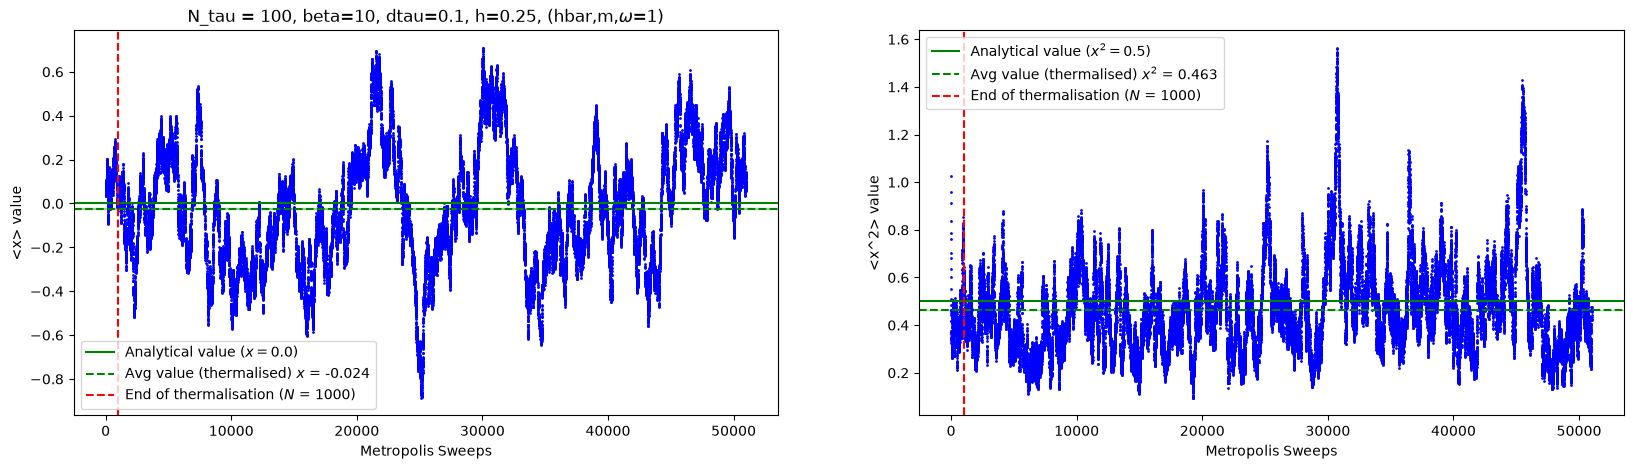

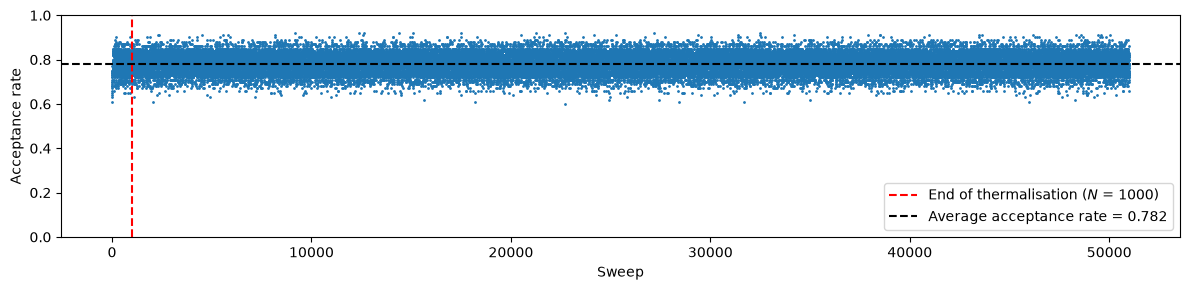

In [28]:
#Defining Parameters
h = 0.25 #step size
m = omega = hbar = 1 #ensuring dimensionless varianbles
N_tau = 100 #size of the lattice
beta = 10
delta_tau = beta / N_tau
N_therm = 1000 #how many of the first sweeps are discarded
N_sweeps = 50000 #how many passes are repeated

#Initialising
x = []
x_2 = []
x_analytical = 0.0
x_2_analytical = hbar / (2*m*omega) * (1 / np.tanh(beta*hbar*omega/2))
path = np.random.randn(N_tau)
total_acc_rate = []

#Running Metropolis-Hastings Algorithm
for i in range(N_therm + N_sweeps):
    total_path, acc_rate = metropolis_sweep(path, delta_tau)
    x.append(np.mean(total_path))
    x_2.append(np.mean(total_path**2))
    total_acc_rate.append(acc_rate)

# Slicing to get rid of first N_therm sweeps for thermalisation
x_thermalised = np.array(x[N_therm:])
x_2_thermalised = np.array(x_2[N_therm:])
total_acc_rate = np.array(total_acc_rate)

x_mean, x_naive_error = np.mean(x_thermalised), naive_error(x_thermalised)
x_2_mean, x_2_naive_error = np.mean(x_2_thermalised), naive_error(x_2_thermalised)

print(f"Acceptance rate = {np.mean(total_acc_rate)}")
print(f"<x>   = {x_mean:.4f} ± {x_naive_error:.4f}")
print(f"<x^2> = {x_2_mean:.4f} ± {x_2_naive_error:.4f}")

# Expectation values vs. sweeps
sweeps = np.arange(len(x))
fig, ax = plt.subplots(1, 2, figsize=(20,5))
ax[0].plot(sweeps, x, 'o', color="blue", markersize=1)
ax[0].set_xlabel("Metropolis Sweeps")
ax[0].set_ylabel("<x> value")
#ax[0].set_ylim(-0.25, 0.25)
ax[0].axhline(y=x_analytical, color='g', linestyle='-', label = f"Analytical value ($x={x_analytical}$)")
ax[0].axhline(y=np.mean(x_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x$ = {np.round(np.mean(x_thermalised), decimals=3)}")
ax[0].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[0].set_title(rf"N_tau = {N_tau}, beta={beta}, dtau={delta_tau}, h={h}, (hbar,m,$\omega$={m})")
ax[0].legend()

ax[1].plot(sweeps, x_2, 'o', color="blue", markersize=1)
ax[1].set_xlabel("Metropolis Sweeps")
ax[1].set_ylabel("<x^2> value")
#ax[1].set_ylim(0.4, 0.6)
ax[1].axhline(y=x_2_analytical, color='g', linestyle='-', label = f"Analytical value ($x^2={np.round(x_2_analytical, 2)}$)")
ax[1].axhline(y=np.mean(x_2_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x^2$ = {np.round(np.mean(x_2_thermalised), decimals=3)}")
ax[1].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[1].legend()

#error bands
ax[0].axhspan(x_mean - x_naive_error, x_mean + x_naive_error, color="green", alpha=0.3)
ax[1].axhspan(x_2_mean - x_2_naive_error, x_2_mean + x_2_naive_error, color="green", alpha=0.3)

# Acceptance rate
plt.figure(figsize=(12,3))
plt.plot(total_acc_rate, '.', markersize=2)
plt.axvline(N_therm, color='red', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
plt.axhline(np.mean(total_acc_rate), linestyle='--', color='black', label=f"Average acceptance rate = {np.round(np.mean(total_acc_rate), decimals=3)}")
plt.ylim(0,1)
plt.xlabel("Sweep")
plt.ylabel("Acceptance rate")
plt.legend()

plt.tight_layout()
plt.show()

<x>   = -0.0655 ± 0.0540  (naive 0.0023)
<x^2> = 0.5202 ± 0.0301  (naive 0.0017)
tau_int(x)   = 282.54  (W=1416),  N_eff = 18
tau_int(x^2) = 154.26  (W=772),  N_eff = 32
<x> is 1.21 true standard errors from 0


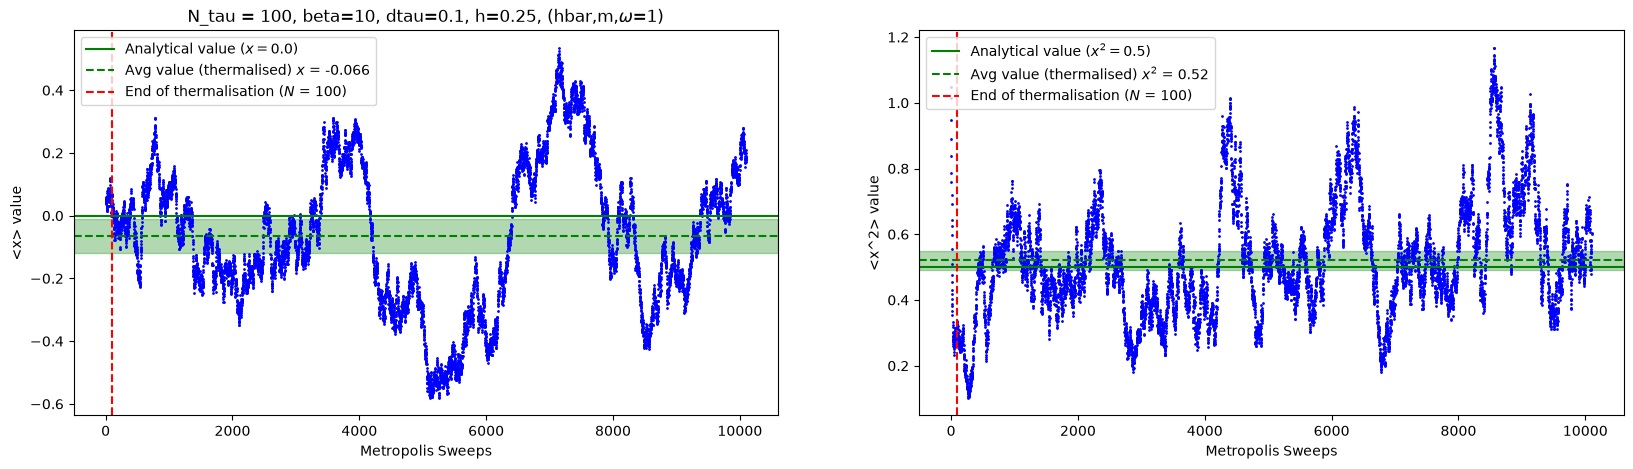

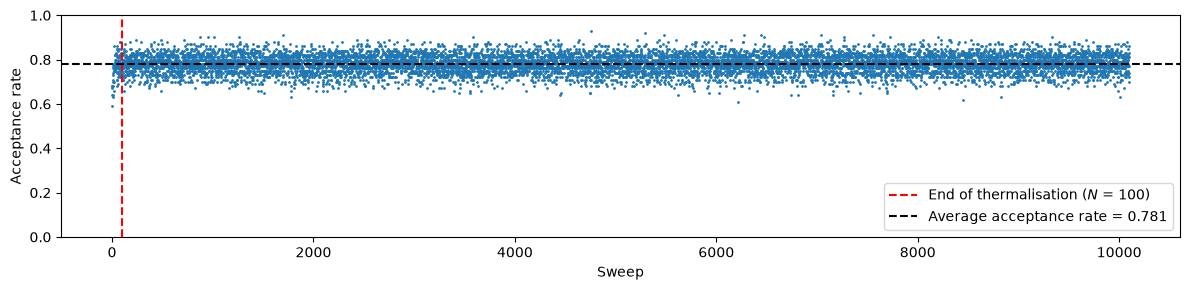

In [14]:
tau_x,  W_x,  C_x,  tau_run_x  = integrated_auto_correlation(x_thermalised)
tau_x_2, W_x_2, C_x_2, tau_run_x_2 = integrated_auto_correlation(x_2_thermalised)

#2*tau=1+2*A
x_true_error = x_naive_error * np.sqrt(2*tau_x) 
x_2_true_error = x_2_naive_error * np.sqrt(2*tau_x_2)

print(f"<x>   = {x_mean:.4f} ± {x_true_error:.4f}  (naive {x_naive_error:.4f})")
print(f"<x^2> = {x_2_mean:.4f} ± {x_2_true_error:.4f}  (naive {x_2_naive_error:.4f})")
print(f"tau_int(x)   = {tau_x:.2f}  (W={W_x}),  N_eff = {N_sweeps/(2*tau_x):.0f}")
print(f"tau_int(x^2) = {tau_x_2:.2f}  (W={W_x_2}),  N_eff = {N_sweeps/(2*tau_x_2):.0f}")
print(f"<x> is {abs(x_mean)/x_true_error:.2f} true standard errors from 0")

fig, ax = plt.subplots(1, 2, figsize=(20,5))
ax[0].plot(sweeps, x, 'o', color="blue", markersize=1)
ax[0].set_xlabel("Metropolis Sweeps")
ax[0].set_ylabel("<x> value")
#ax[0].set_ylim(-0.25, 0.25)
ax[0].axhline(y=x_analytical, color='g', linestyle='-', label = f"Analytical value ($x={x_analytical}$)")
ax[0].axhline(y=np.mean(x_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x$ = {np.round(np.mean(x_thermalised), decimals=3)}")
ax[0].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[0].set_title(rf"N_tau = {N_tau}, beta={beta}, dtau={delta_tau}, h={h}, (hbar,m,$\omega$={m})")
ax[0].legend()

ax[1].plot(sweeps, x_2, 'o', color="blue", markersize=1)
ax[1].set_xlabel("Metropolis Sweeps")
ax[1].set_ylabel("<x^2> value")
#ax[1].set_ylim(0.4, 0.6)
ax[1].axhline(y=x_2_analytical, color='g', linestyle='-', label = f"Analytical value ($x^2={np.round(x_2_analytical, 2)}$)")
ax[1].axhline(y=np.mean(x_2_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x^2$ = {np.round(np.mean(x_2_thermalised), decimals=3)}")
ax[1].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[1].legend()

#error bands
ax[0].axhspan(x_mean - x_true_error, x_mean + x_true_error, color="green", alpha=0.3)
ax[1].axhspan(x_2_mean - x_2_true_error, x_2_mean + x_2_true_error, color="green", alpha=0.3)

# Acceptance rate
plt.figure(figsize=(12,3))
plt.plot(total_acc_rate, '.', markersize=2)
plt.axvline(N_therm, color='red', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
plt.axhline(np.mean(total_acc_rate), linestyle='--', color='black', label=f"Average acceptance rate = {np.round(np.mean(total_acc_rate), decimals=3)}")
plt.ylim(0,1)
plt.xlabel("Sweep")
plt.ylabel("Acceptance rate")
plt.legend()


plt.tight_layout()
plt.show()

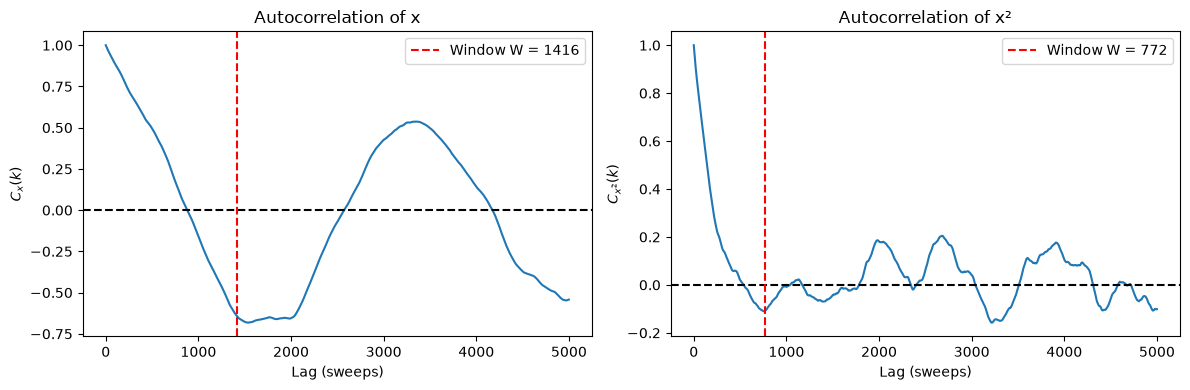

In [29]:

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(np.arange(len(C_x)), C_x)
ax[0].axhline(0, color="black", linestyle="--")
ax[0].axvline(W_x, color="red", linestyle="--",
              label=f"Window W = {W_x}")
ax[0].set_xlabel("Lag (sweeps)")
ax[0].set_ylabel(r"$C_x(k)$")
ax[0].set_title("Autocorrelation of x")
ax[0].legend()

ax[1].plot(np.arange(len(C_x_2)), C_x_2)
ax[1].axhline(0, color="black", linestyle="--")
ax[1].axvline(W_x_2, color="red", linestyle="--",
              label=f"Window W = {W_x_2}")
ax[1].set_xlabel("Lag (sweeps)")
ax[1].set_ylabel(r"$C_{x^2}(k)$")
ax[1].set_title("Autocorrelation of x²")
ax[1].legend()

plt.tight_layout()
plt.show()

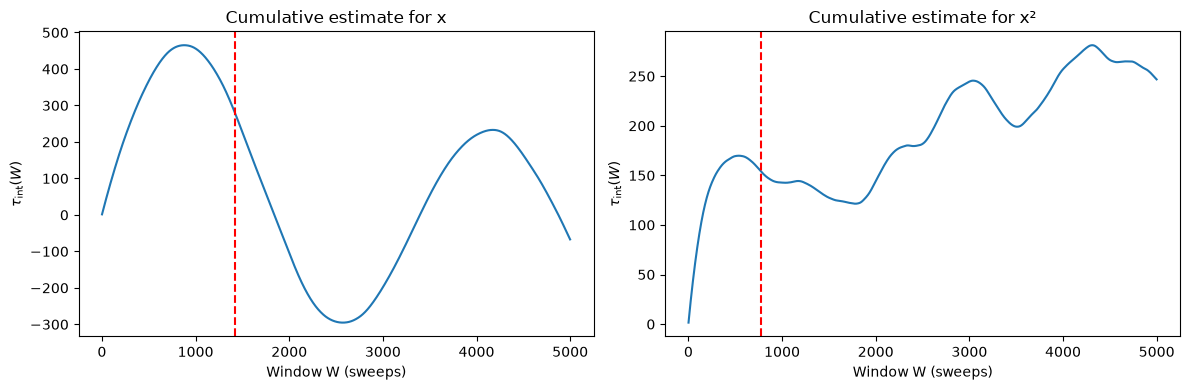

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(np.arange(1, len(tau_run_x) + 1),tau_run_x)
ax[0].axvline(W_x, color="red", linestyle="--")
ax[0].set_xlabel("Window W (sweeps)")
ax[0].set_ylabel(r"$\tau_{\mathrm{int}}(W)$")
ax[0].set_title("Cumulative estimate for x")

ax[1].plot(np.arange(1, len(tau_run_x_2) + 1), tau_run_x_2)
ax[1].axvline(W_x_2, color="red", linestyle="--")
ax[1].set_xlabel("Window W (sweeps)")
ax[1].set_ylabel(r"$\tau_{\mathrm{int}}(W)$")
ax[1].set_title("Cumulative estimate for x²")

plt.tight_layout()
plt.show()


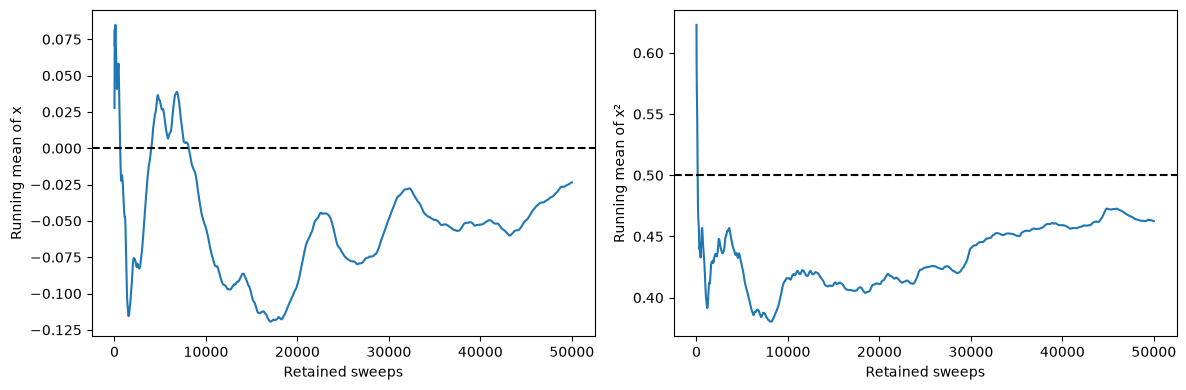

In [31]:
x_thermalised = np.asarray(x[N_therm:])
x2_thermalised = np.asarray(x_2[N_therm:])

running_x = np.cumsum(x_thermalised) / np.arange(
    1, len(x_thermalised) + 1
)

running_x2 = np.cumsum(x2_thermalised) / np.arange(
    1, len(x2_thermalised) + 1
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(running_x)
ax[0].axhline(0, linestyle="--", color="black")
ax[0].set_xlabel("Retained sweeps")
ax[0].set_ylabel("Running mean of x")

ax[1].plot(running_x2)
ax[1].axhline(0.5, linestyle="--", color="black")
ax[1].set_xlabel("Retained sweeps")
ax[1].set_ylabel("Running mean of x²")

plt.tight_layout()
plt.show()

In [32]:
results = []

for seed in range(5):
    np.random.seed(seed)
    path_run = np.random.randn(N_tau)

    # Use your existing Metropolis functions.
    measurements_x = []
    measurements_x2 = []

    for sweep in range(N_therm + N_sweeps):
        path_run, acc_rate = metropolis_sweep(
            path_run, delta_tau
        )

        if sweep >= N_therm:
            measurements_x.append(np.mean(path_run))
            measurements_x2.append(np.mean(path_run**2))

    results.append((
        np.mean(measurements_x),
        np.mean(measurements_x2)
    ))

for i, (mean_x, mean_x2) in enumerate(results):
    print(
        f"Chain {i}: <x> = {mean_x:.4f}, "
        f"<x^2> = {mean_x2:.4f}"
    )

Chain 0: <x> = 0.0203, <x^2> = 0.5078
Chain 1: <x> = -0.0409, <x^2> = 0.4873
Chain 2: <x> = 0.0725, <x^2> = 0.5019
Chain 3: <x> = -0.0450, <x^2> = 0.4607
Chain 4: <x> = 0.0223, <x^2> = 0.5246
